# Evidence 7 — Fog-Aware Diagnostic and Visualization

**Purpose:** Examine the previously captured **post-burn-in diagnostic log**. This notebook only reads a CSV and makes charts; it **does not** load a checkpoint, train, or run inference.

**Required file:** Put `post_burnin_diagnostic_records.csv` inside an `evidence_data` folder beside this notebook. It is the original validated CSV from RunPod; **do not replace it with fabricated example records**.

## Cell 1 — Import libraries

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Cell 2 — Locate the evidence CSV

The notebook is portable because it uses a path relative to the notebook folder.

In [5]:
BASE = Path.cwd()
CSV = BASE / "evidence_data" / "post_burnin_diagnostic_records.csv"
CHARTS = BASE / "charts"
CHARTS.mkdir(exist_ok=True)
print("Looking for:", CSV)
assert CSV.is_file(), "Copy the original diagnostic CSV into evidence_data/ first."

Looking for: /workspace/Adaptive_teacher_Experiment/evidence_data/post_burnin_diagnostic_records.csv


## Cell 3 — Read and inspect the records

In [6]:
records = pd.read_csv(CSV)
display(records.head(5))
print("Rows:", len(records))

,iteration,threshold,retained_pseudo_labels,filename,fog_level
0,1001,0.8,15,/workspace/datasets/cityscapes_foggy/leftImg8b...,light
1,1001,0.8,8,/workspace/datasets/cityscapes_foggy/leftImg8b...,light
2,1001,0.7,12,/workspace/datasets/cityscapes_foggy/leftImg8b...,medium
3,1001,0.7,3,/workspace/datasets/cityscapes_foggy/leftImg8b...,medium
4,1001,0.8,7,/workspace/datasets/cityscapes_foggy/leftImg8b...,strong


Rows: 23


## Cell 4 — Check required columns and record coverage

In [7]:
required = {"iteration", "filename", "fog_level", "threshold", "retained_pseudo_labels"}
assert required.issubset(records.columns), required - set(records.columns)
assert len(records) == 23, "Unexpected record count; inspect the source CSV."
iterations = sorted(records["iteration"].astype(int).unique())
assert iterations == list(range(1001, 1020)), "Unexpected diagnostic iteration range."
print("Validated iterations:", iterations[0], "to", iterations[-1])

Validated iterations: 1001 to 1019


## Cell 5 — Verify the applied fog-aware thresholds

In [8]:
expected = {"light": 0.80, "medium": 0.70, "strong": 0.80}
assert set(records["fog_level"]) == set(expected)
for fog, threshold in expected.items():
    actual = records.loc[records["fog_level"] == fog, "threshold"]
    assert np.allclose(actual, threshold), f"Unexpected threshold for {fog}"
assert (records["retained_pseudo_labels"] >= 0).all()
print("PASS: all three fog thresholds match the expected configuration")

PASS: all three fog thresholds match the expected configuration


## Cell 6 — Summarize actual samples and retained labels

In [9]:
order = ["light", "medium", "strong"]
summary = records.groupby("fog_level").agg(
    image_records=("filename", "size"),
    total_retained=("retained_pseudo_labels", "sum"),
    mean_retained=("retained_pseudo_labels", "mean"),
    threshold=("threshold", "first")
).reindex(order)
display(summary.round(2))

,image_records,total_retained,mean_retained,threshold
fog_level,,,,
light,10,80,8.00,0.8
medium,6,79,13.17,0.7
strong,7,63,9.00,0.8


## Cell 7 — Plot applied confidence thresholds

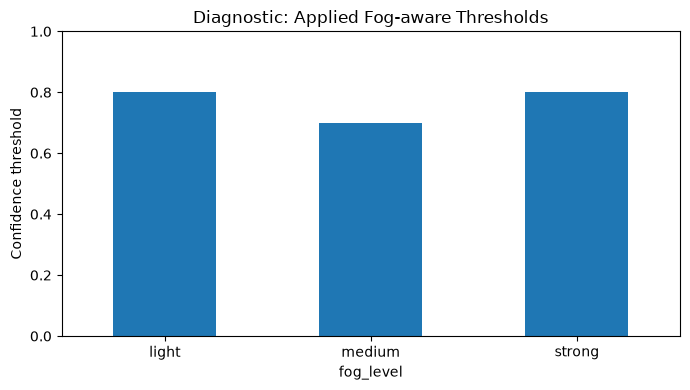

In [10]:
ax = summary["threshold"].plot.bar(figsize=(7, 4), rot=0)
ax.set(title="Diagnostic: Applied Fog-aware Thresholds", ylabel="Confidence threshold", ylim=(0, 1))
plt.tight_layout()
plt.savefig(CHARTS / "04_diagnostic_thresholds.png", dpi=200)
plt.show()

## Cell 8 — Plot sampled records by fog density

These counts describe this short diagnostic only, not the full historical training distribution.

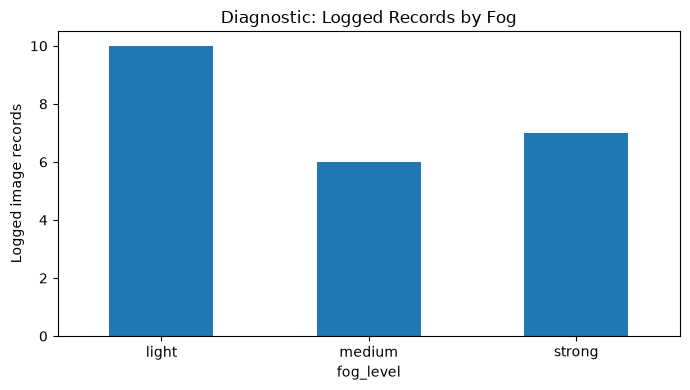

In [11]:
ax = summary["image_records"].plot.bar(figsize=(7, 4), rot=0)
ax.set(title="Diagnostic: Logged Records by Fog", ylabel="Logged image records")
plt.tight_layout()
plt.savefig(CHARTS / "05_diagnostic_fog_records.png", dpi=200)
plt.show()

## Cell 9 — Plot average retained pseudo-labels

Averages are descriptive; the small and uneven sample sizes do not establish a reliable population-level difference.

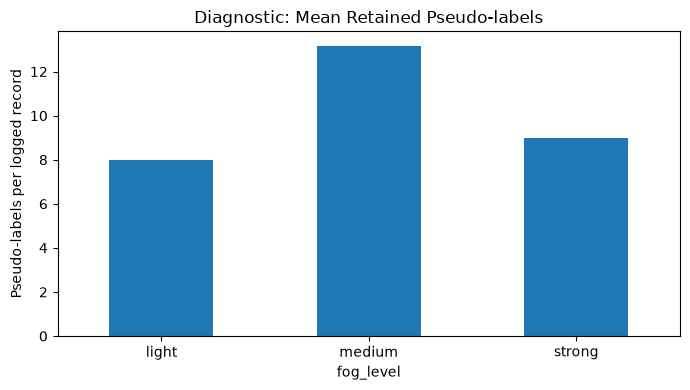

In [12]:
ax = summary["mean_retained"].plot.bar(figsize=(7, 4), rot=0)
ax.set(title="Diagnostic: Mean Retained Pseudo-labels", ylabel="Pseudo-labels per logged record")
plt.tight_layout()
plt.savefig(CHARTS / "06_diagnostic_retention.png", dpi=200)
plt.show()

## Cell 10 — Save a small analysis summary

In [13]:
summary.to_csv(BASE / "diagnostic_analysis_summary.csv")
print("Saved:", BASE / "diagnostic_analysis_summary.csv")
print("Charts saved in:", CHARTS)

Saved: /workspace/Adaptive_teacher_Experiment/diagnostic_analysis_summary.csv
Charts saved in: /workspace/Adaptive_teacher_Experiment/charts


## Interpretation and limitations

- The original diagnostic captured 23 logged records from iterations 1001–1019, spanning all three fog levels.
- The diagnostic loaded the final Fog-Aware 05C checkpoint and started its iteration counter at 1001; **it was not a reproduction of historical iteration 1001**.
- Diagnostic labeled and unlabeled batch sizes were reduced to one each to fit the 16 GB GPU.
- End-of-training validation failed because a Foggy Cityscapes validation annotation was unavailable. The pseudo-label log was captured before this failure.
- This evidence supports that the instrumented diagnostic applied the intended per-fog thresholds. It does **not** prove identical historical sampling or that Fog-Aware 05C outperforms Adaptive Teacher.

Keep the original `post_burnin_training_log.jsonl` and `diagnostic_console.log` as raw audit evidence if your supervisor requests them.